<a href="https://colab.research.google.com/github/balakarthikas/Balakarthika-S/blob/main/python(EDA)project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Sales Data Analysis Project - EDA Overview

1.Understand the dataset structure
2.Check data types and missing values
3.Detect duplicates
4.Perform statistical summary
5.Explore sales and profit distribution
6.Analyze performance by region and category
7.Extract time-based insights
8.Generate business insights

What we are to discover in this project

1. The highest revenue-generate region
2. The most profitable product category
3. The best-selling product
4. Monthly sales performance trends
5. Overall profit distribution

Step1-Data Loading & Overview

In [1]:
!pip install pandas

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
#load dataset
df=pd.read_csv('/content/Sales_Project_Dataset.csv')
df

,Order_ID,Product,Category,Quantity,Unit_Price,Sales,Profit,Region,Payment_Method,Order_Date
0,ORD-1000,Keyboard,Accessories,7,910,6370,2717.61,West,Card,3/13/2023
1,ORD-1001,Keyboard,Accessories,5,171,855,374.15,North,Card,11/27/2023
2,ORD-1002,Phone,Electronics,8,1446,11568,3002.52,East,Transfer,6/1/2023
3,ORD-1003,Laptop,Electronics,3,1382,4146,464.50,West,Transfer,10/21/2023
4,ORD-1004,Headphones,Accessories,2,1265,2530,260.88,West,Card,6/10/2023
...,...,...,...,...,...,...,...,...,...,...
300,ORD-1189,Headphones,Accessories,7,799,5593,1119.46,East,Transfer,10/1/2023
301,ORD-1123,Mouse,Accessories,4,940,3760,1560.06,North,Transfer,2/22/2023
302,ORD-1185,Tablet,Electronics,1,1326,1326,139.89,East,Card,10/30/2023
303,ORD-1213,Mouse,Accessories,2,370,740,328.91,West,Transfer,11/25/2023


In [6]:
#preview the first 5 rows
df.head(5)

,Order_ID,Product,Category,Quantity,Unit_Price,Sales,Profit,Region,Payment_Method,Order_Date,profit_margin
0,ORD-1000,Keyboard,Accessories,7,910,6370,2717.61,West,Card,3/13/2023,42.662637
1,ORD-1001,Keyboard,Accessories,5,171,855,374.15,North,Card,11/27/2023,43.760234
2,ORD-1002,Phone,Electronics,8,1446,11568,3002.52,East,Transfer,6/1/2023,25.955394
3,ORD-1003,Laptop,Electronics,3,1382,4146,464.50,West,Transfer,10/21/2023,11.203570
4,ORD-1004,Headphones,Accessories,2,1265,2530,260.88,West,Card,6/10/2023,10.311462


Check dataset properties

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 305 entries, 0 to 304
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        305 non-null    object 
 1   Product         305 non-null    object 
 2   Category        305 non-null    object 
 3   Quantity        305 non-null    int64  
 4   Unit_Price      305 non-null    int64  
 5   Sales           305 non-null    int64  
 6   Profit          305 non-null    float64
 7   Region          295 non-null    object 
 8   Payment_Method  295 non-null    object 
 9   Order_Date      305 non-null    object 
dtypes: float64(1), int64(3), object(6)
memory usage: 24.0+ KB


In [ ]:
df.describe()

,Quantity,Unit_Price,Sales,Profit
count,305.000000,305.000000,305.000000,305.000000
mean,4.862295,796.593443,3942.190164,1163.626361
std,2.584249,407.154017,3127.063316,1145.894864
min,1.000000,56.000000,111.000000,14.750000
25%,3.000000,471.000000,1326.000000,328.910000
50%,5.000000,800.000000,3008.000000,773.120000
75%,7.000000,1142.000000,5860.000000,1579.630000
max,9.000000,1492.000000,12888.000000,6092.060000


Step2-Missing Values Handling

In [ ]:
#check missing values
df.isnull().sum()

,0
Order_ID,0
Product,0
Category,0
Quantity,0
Unit_Price,0
Sales,0
Profit,0
Region,10
Payment_Method,10
Order_Date,0


In [ ]:
#filling missing region with unknow
df['Region']=df['Region'].fillna('unknow')

In [ ]:
#filling missing payment with the frequent value
df['Payment_Method']=df['Payment_Method'].fillna(df['Payment_Method'].mode()[0])

In [ ]:
df.isnull().sum()

,0
Order_ID,0
Product,0
Category,0
Quantity,0
Unit_Price,0
Sales,0
Profit,0
Region,0
Payment_Method,0
Order_Date,0


Step3-Duplicate Detection & Removel

In [ ]:
#check duplicate rows
df.duplicated().sum()

np.int64(5)

In [ ]:
#remove duplicate
df=df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

Step4-Feature Engineering

In [ ]:
df=df.copy()

In [5]:
#create profit margin column
df['profit_margin']=(df['Profit']/df['Sales'])*100

Convert Date & Extract Month/Year

In [7]:
#convert order_date to datetime
df['Order_Date']=pd.to_datetime(df['Order_Date'])

In [8]:
#Extract Month
df['Month']=df['Order_Date'].dt.month

In [9]:
#Extract Year
df['Year']=df['Order_Date'].dt.year

In [10]:
df.head(5)

,Order_ID,Product,Category,Quantity,Unit_Price,Sales,Profit,Region,Payment_Method,Order_Date,profit_margin,Month,Year
0,ORD-1000,Keyboard,Accessories,7,910,6370,2717.61,West,Card,2023-03-13,42.662637,3,2023
1,ORD-1001,Keyboard,Accessories,5,171,855,374.15,North,Card,2023-11-27,43.760234,11,2023
2,ORD-1002,Phone,Electronics,8,1446,11568,3002.52,East,Transfer,2023-06-01,25.955394,6,2023
3,ORD-1003,Laptop,Electronics,3,1382,4146,464.50,West,Transfer,2023-10-21,11.203570,10,2023
4,ORD-1004,Headphones,Accessories,2,1265,2530,260.88,West,Card,2023-06-10,10.311462,6,2023


Step5-Grouping & Aggregation

Sale by Region

In [11]:
sales_by_region=df.groupby('Region')['Sales'].sum()

In [12]:
sales_by_region

,Sales
Region,
East,290002
North,281452
South,279651
West,295023


Profit by category


In [13]:
profit_by_category=df.groupby('Category')['Profit'].sum()

In [14]:
profit_by_category

,Profit
Category,
Accessories,171946.79
Electronics,182959.25


Monthly sale trend

In [15]:
monthly_sales=df.groupby('Month')['Sales'].sum()

In [16]:
monthly_sales

,Sales
Month,
1,93195
2,117070
3,89541
4,106941
5,94977
6,121350
7,68552
8,107781
9,91142


Step 6-Visualization

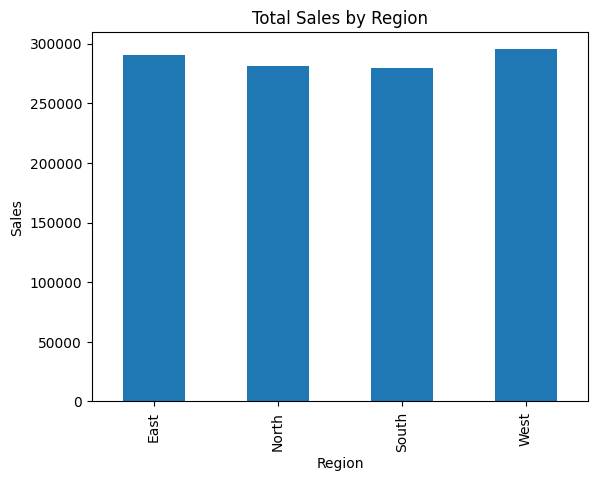

In [17]:
#sales by region
sales_by_region.plot(kind="bar")
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.show()

Monthly sales trend

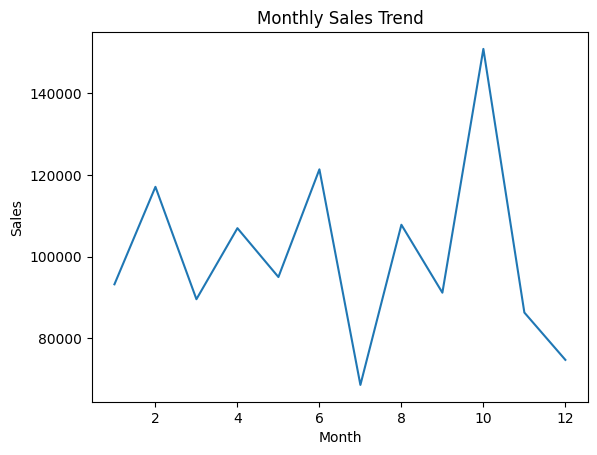

In [19]:
monthly_sales.plot(kind="line")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.show()

Histogram- Sales Distribution

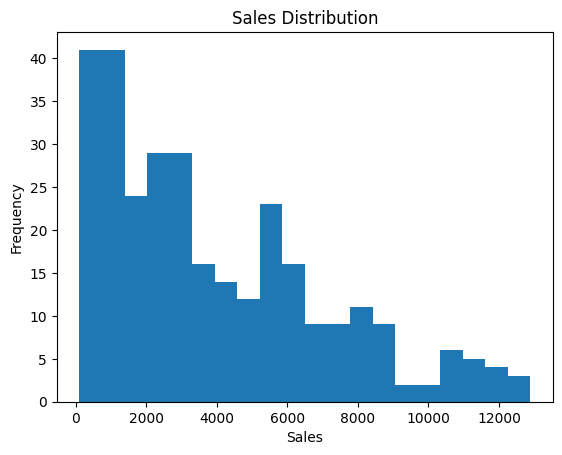

In [20]:
df['Sales'].plot(kind="hist",bins=20)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.show()



Profit Distribution

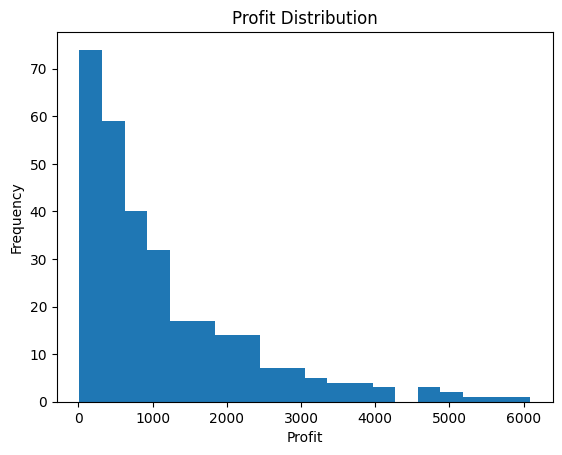

In [21]:
df["Profit"].plot(kind="hist",bins=20)
plt.title("Profit Distribution")
plt.xlabel("Profit")
plt.show()

Step 7-Business Insights

In [22]:
#Best selling product
Best_selling=df.groupby("Product")['Quantity'].sum().sort_values(ascending=False)

In [23]:
Best_selling

,Quantity
Product,
Keyboard,254
Tablet,223
Mouse,214
Monitor,203
Headphones,201
Laptop,196
Phone,192


In [24]:
#most profitable category
profit_by_category.sort_values(ascending=False)

,Profit
Category,
Electronics,182959.25
Accessories,171946.79


Region Performance

In [25]:
sales_by_region.sort_values(ascending=False)

,Sales
Region,
West,295023
East,290002
North,281452
South,279651
